# E74: Where does the masked forward lose a weight change?

*Independent check: no bug, the claim holds with a wording change, applied here. `reports/reviews/2026-11-03_review_e72-e74-independent-check.md`. Report: `reports/analyses/2026-11-03_analysis_e72-d1-second-test.md`.*

## The answer

With every matrix masked by the original model's masks, fixed or stochastic, the whole update shifts the logits by a small fraction of its clean amplitude. The last matrix alone passes nearly all of its change, so the added term does enter. A random change of equal clean effect is lost at early blocks too. Why the masks lose the update is not shown. One temperature removes about half of the gold updates' distance from the original model, and little of the template's.


## What we were trying to test

D1 is a map that keeps the decomposition faithful for a real update, and it needs a test that can pass a good placement. Under the original model's masks, nothing has passed. This job asks where a change is lost.

**The read.** A change enters as an unmasked term $x\,\delta W^\top$ at its matrix, with W0's masks fixed and Δ off.

- **Transmission** is KL(masked W0 ‖ masked W0 + change) over KL(W0 ‖ W0 + change). It reads 1 if the masked forward responds as the clean model does, 0 if it ignores the change.
- **Amplitude** is the masked logit shift's norm over the clean one's. KL is quadratic, so amplitude is the less extreme number, and has no direction.

**The arms.**

- *One block's change*, at blocks 0, 7, 14, 21 and 27, and the whole update.
- *A Gaussian in the same matrices*, scaled to the same clean KL: is the loss general, or special to the update?
- *The last matrix alone*, with only the final norm and unembedding after it: the control.
- *Masks only upstream of the change, and only at and after it* (Amendment 1): which masks cost what?
- *Later matrices frozen at their clean output*, clean model (Amendment 2): how much of a change's clean effect reaches the logits without later blocks?
- *VPD's stochastic masks* (Amendment 2): do off subcomponents left partly on hear it?
- *One temperature on W0's logits*: how much of the distance from W0 is sharpness?

The first fine-tune at step 10 and the template at step 100, on 32 rows each; temperature on four updates.

## What we expected, and why

Block 0's change would keep half its KL with later sites unmasked, so the loss would be downstream. A Gaussian would pass within a factor 3 of the update. The gap would then be amplification, since the update's clean effect is thousands of times a Gaussian's per unit norm. Stochastic masks would pass between 0.05 and 0.25 or better, because they open off subcomponents by a half on average. One temperature would leave between 0.4 and 1.0 on the gold updates, because 19% of top tokens differ, and do nothing on the template.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_transmission")
RES, FIG = ROOT / "results", ROOT / "figures"

def load(rel):
    return json.loads((RES / rel).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

PANELS = (("u1", "first fine-tune, step 10"), ("u3", "template, step 100"))


## What we observed

### How much of a weight change reaches the logits under W0's fixed masks?


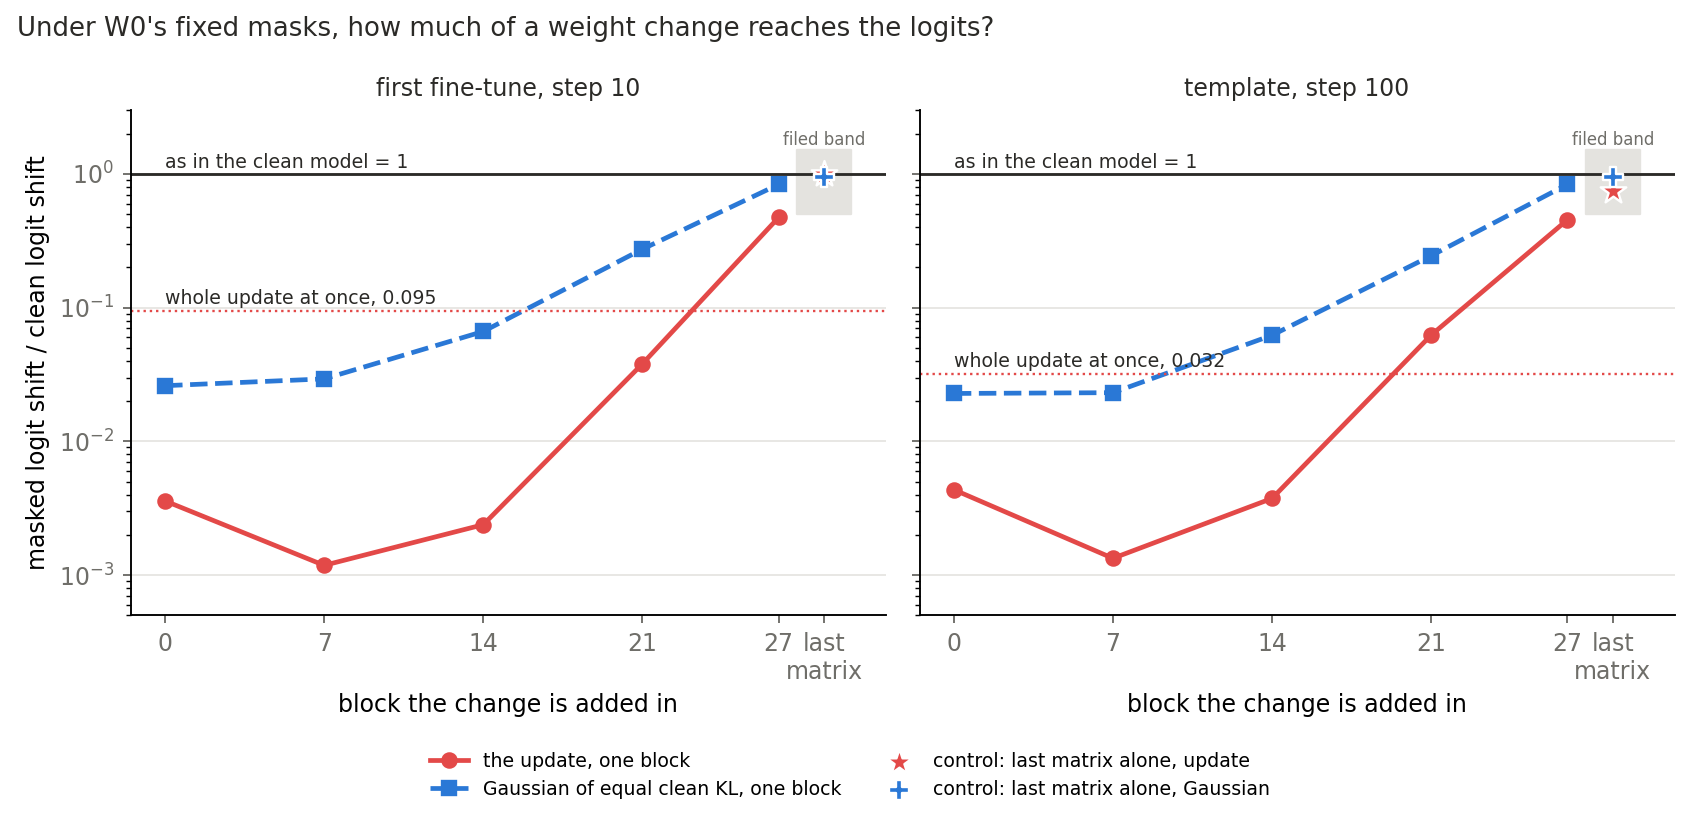

| transmission / amplitude | first fine-tune, step 10 | template, step 100 |
|---|---|---|
| whole update | 0.0055 / 0.095 | 0.0004 / 0.032 |
| last matrix, update | 0.7853 / 0.991 | 0.4475 / 0.752 |
| last matrix, Gaussian | 0.6933 / 0.952 | 0.6904 / 0.948 |

In [2]:
show("by_block.png")
rows = []
for name, get in (("whole update", lambda u: load(f"{u}/all.json")["summary"]["all"]),
                  ("last matrix, update", lambda u: load(f"{u}/control.json")["summary"]["dw_down27"]),
                  ("last matrix, Gaussian", lambda u: load(f"{u}/control.json")["summary"]["gauss_down27"])):
    rows.append([name, *(f"{get(u)['tau']:.4f} / {get(u)['amp']:.3f}" for u, _ in PANELS)])
table(["transmission / amplitude", *[lab for _, lab in PANELS]], rows)


**Reading it.** Barely, except at the very end. The whole update reaches the logits at an amplitude of 0.095 and 0.032, a transmission of 0.0055 and 0.0004. Early blocks' changes read about 0.001 to 0.004. That is about what 1-3% of the update does in the clean model. The last matrix passes at 0.99 and 0.75, so the term enters. But that control cannot fail through later masks, since none follow it, and no control shows a change expected to pass does pass at an early block. Its first filed band stopped a job at 0.447 on the template, and was rewritten after seeing the values.


### Do VPD's own stochastic masks hear the update better?


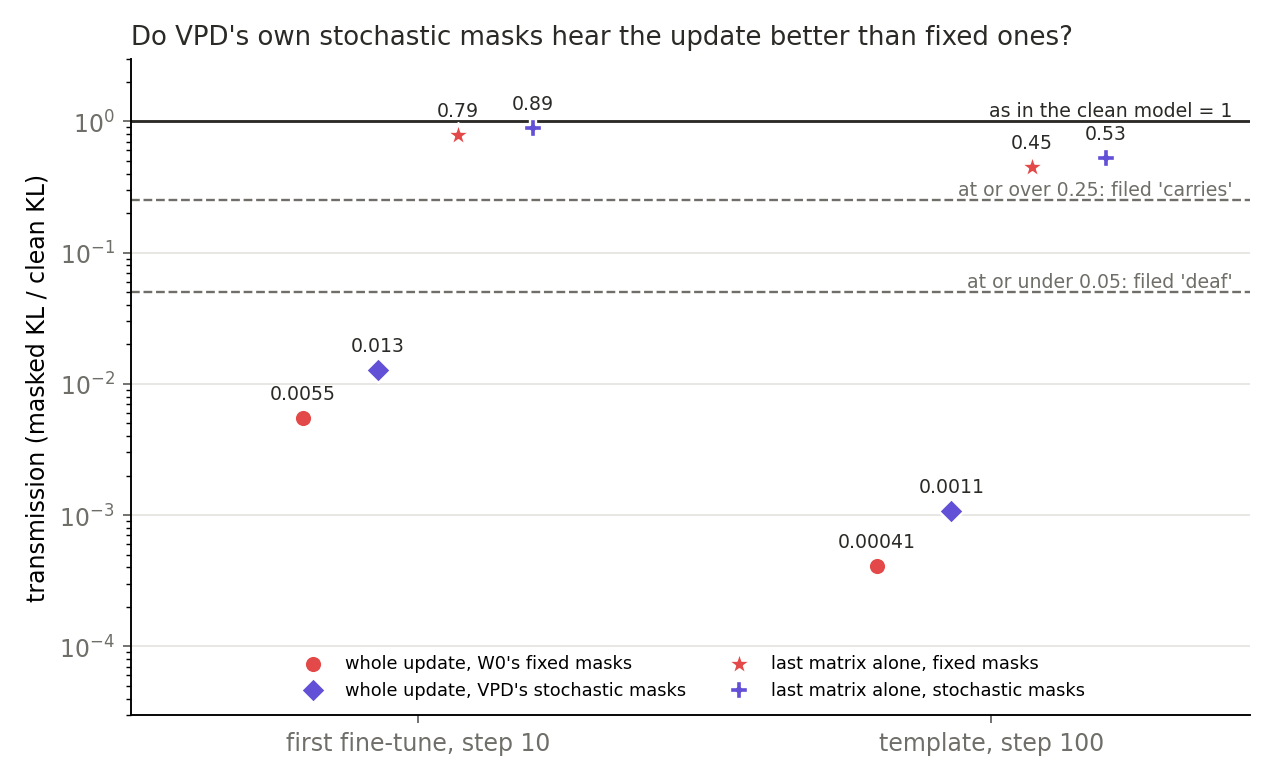

In [3]:
show("stochastic.png")


**Reading it.** No, and our lean missed. The whole update reads 0.013 and 0.0011, under the filed "deaf" line of 0.05, at amplitudes of 0.13 and 0.05. This is one draw per row at one seed. W0's own KL from its masked forward falls from 0.067 to 0.044 under these masks, so they are gentler on W0 without being more responsive to the change.


### Which masks cost a change most?


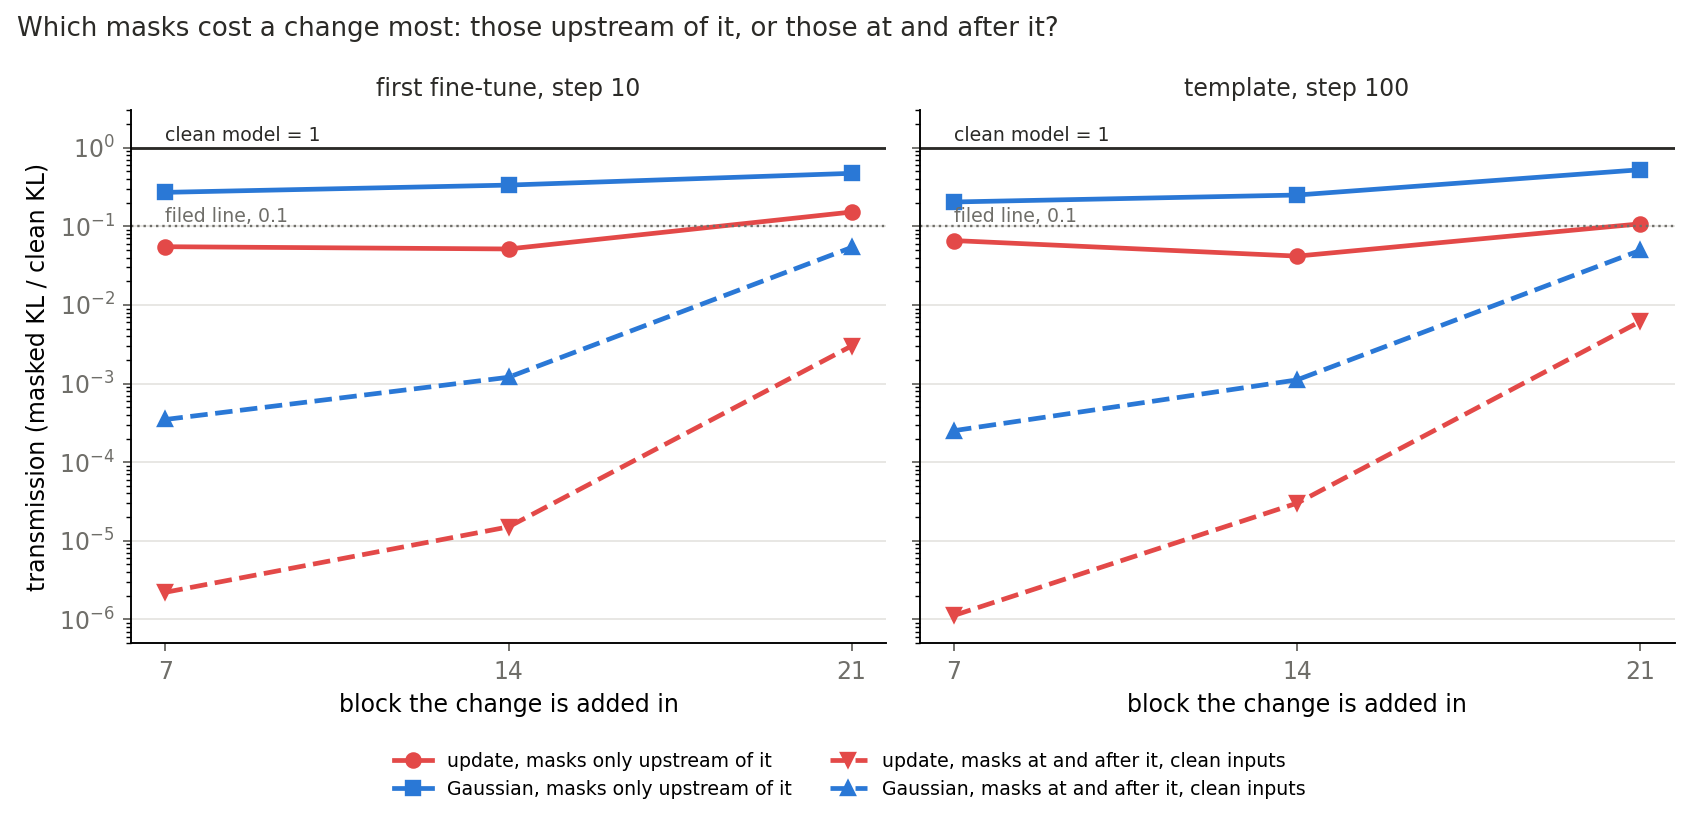

In [4]:
show("factor.png")


**Reading it.** Mostly those at and after the change, for the update and a Gaussian alike. With every mask on and clean inputs for the added term, the update transmits under 4e-5 at blocks 0 to 14 and a Gaussian about 1e-3. With masks only upstream, the update keeps 0.04 to 0.15 and a Gaussian 0.20 to 0.52. Every filed label here came as leaned. The lean on block 0 with later sites unmasked missed, at 0.057 and 0.034 against 0.5.


### How far does the masked forward run from the clean one?


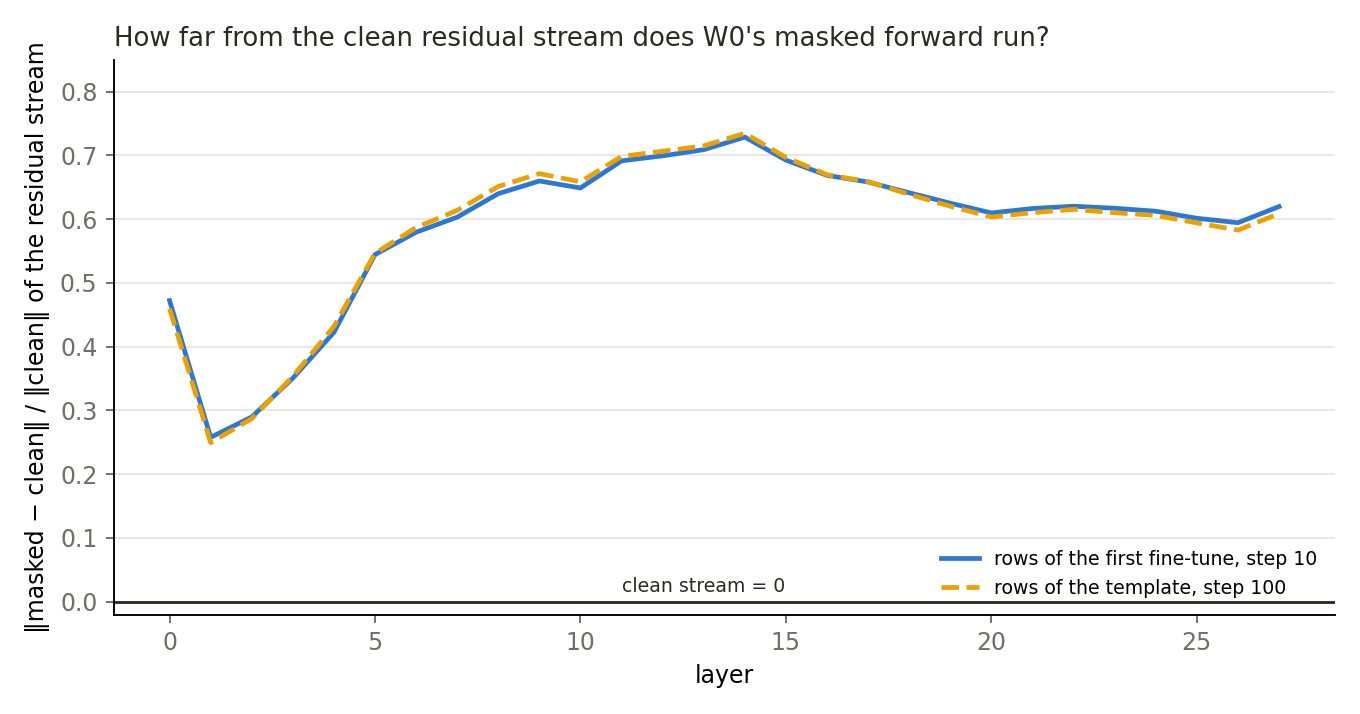

In [5]:
show("stream_gap.png")


**Reading it.** Far. The residual stream sits 25% to 73% of its own norm from the clean one at every layer, while KL(W0 ‖ masked W0) is about 0.07. So the masked forward may be a different network reaching the same logits. That is one of the alternatives below, not a finding.


### Is the gap between update and Gaussian about switched-off subcomponents?


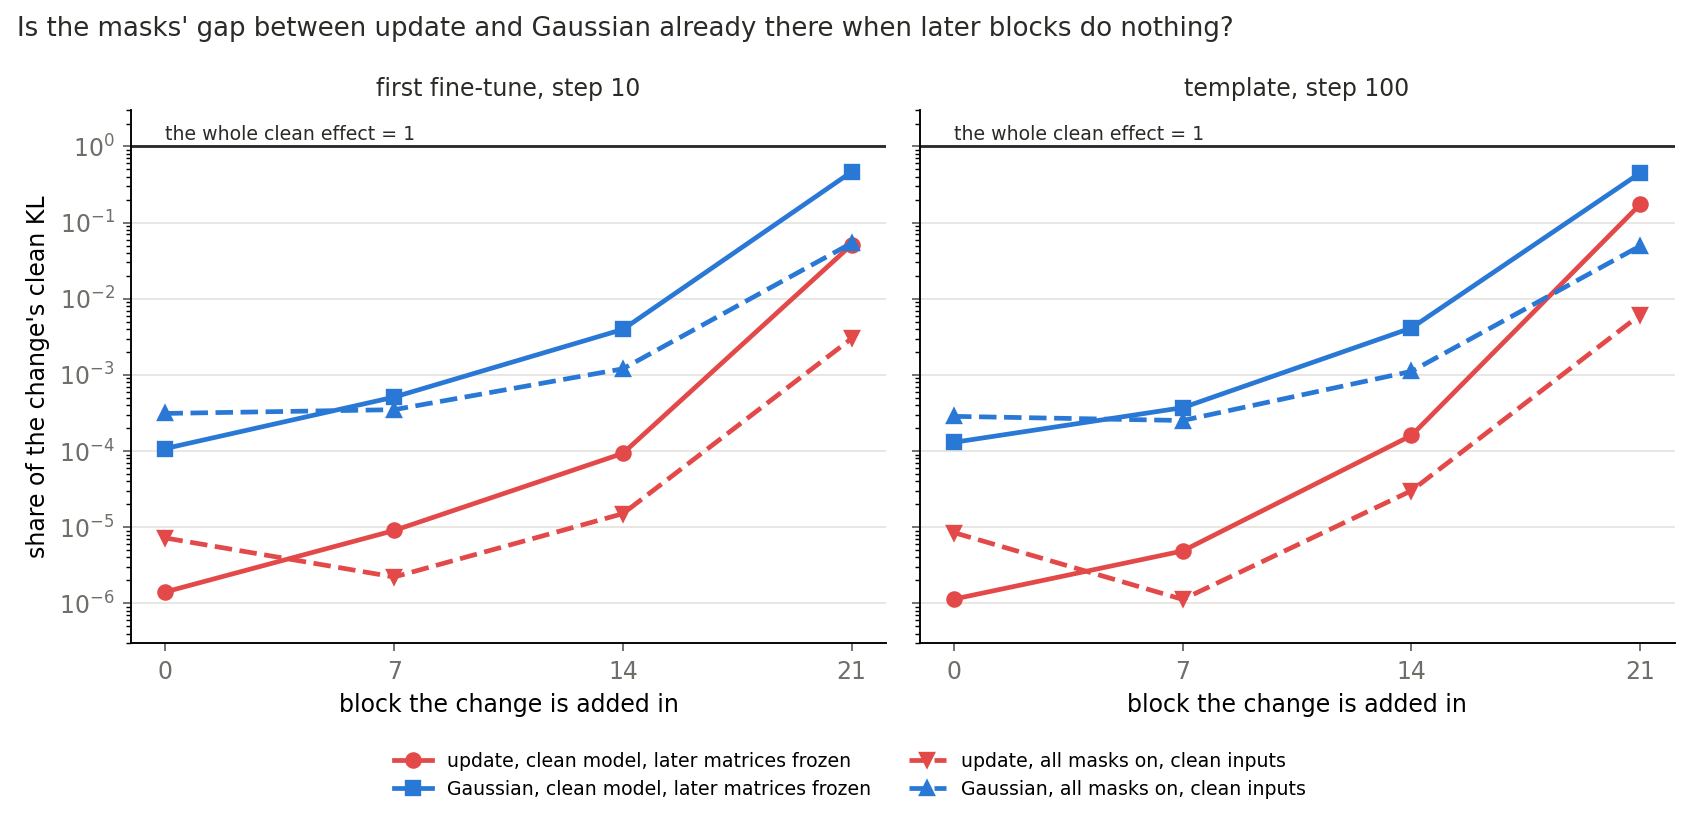

In [6]:
show("direct.png")


**Reading it.** The filed label says yes, and the frozen read weakens that reading without settling it. The filed rule reads "needs switched-off subcomponents", because a Gaussian passes 34 to 262 times the update's share at blocks 0, 7 and 14. With later matrices frozen in the clean model, a Gaussian keeps 26 to 115 times the update's share, and the filed label is "amplification", as leaned. So the masks' gap is about as large as a gap already there with no masks at all: their ratio is 0.29 to 3.1. Two things stop this clearing the label. With masks only upstream and later blocks intact, a Gaussian still passes 3.1 to 6.5 times the update's share, and amplification cannot produce that. And matching Gaussians have 48 to 171 times the update's norm.


### How much of the fine-tuned model's distance from W0 can one temperature remove?


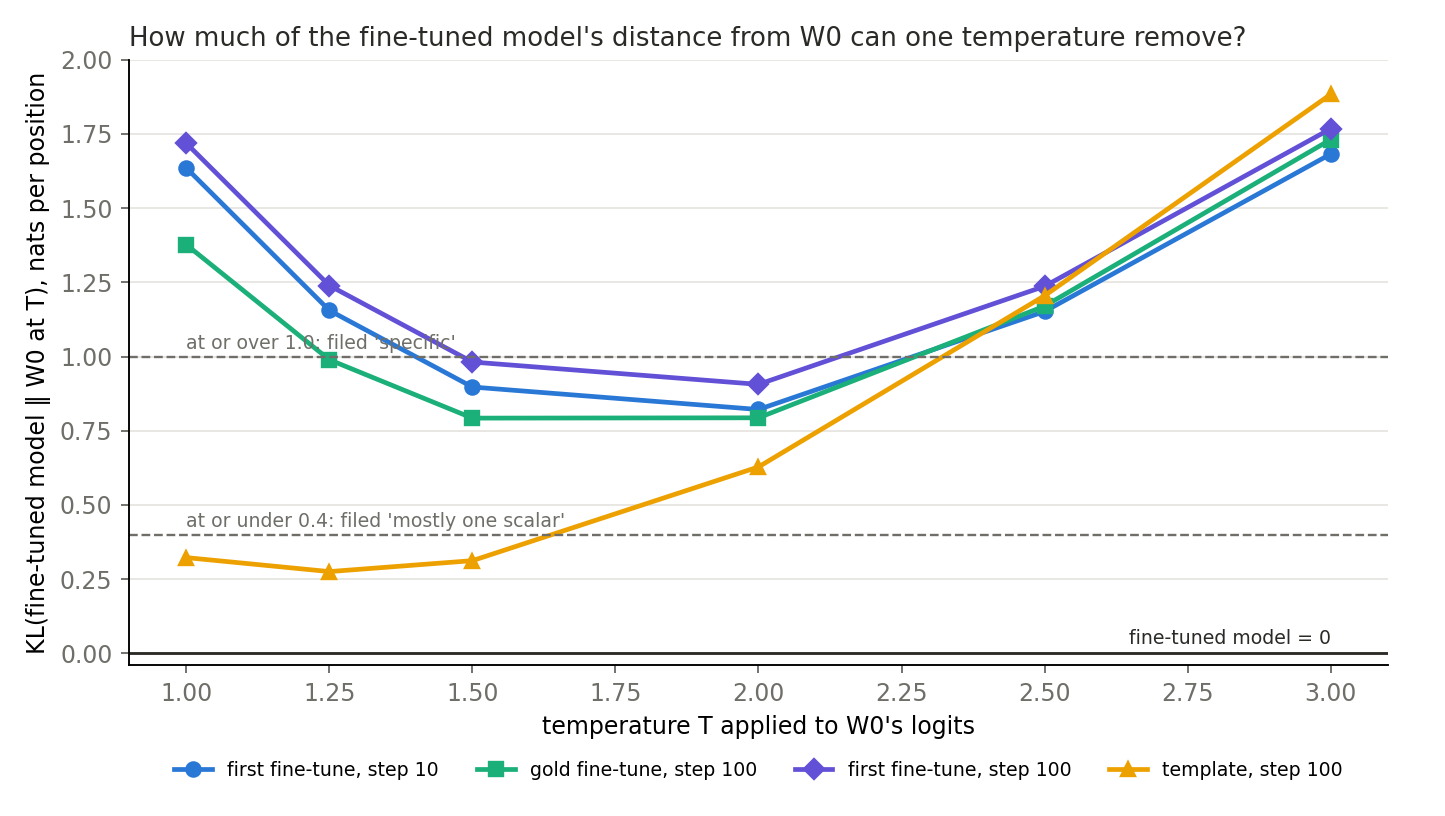

| update | at T = 1 | lowest | share removed | filed label |
|---|---|---|---|---|
| first, step 10 | 1.635 | 0.822 | 0.498 | between |
| gold, step 100 | 1.377 | 0.793 | 0.424 | between |
| first, step 100 | 1.718 | 0.906 | 0.473 | between |
| template, step 100 | 0.323 | 0.276 | 0.146 | no gain |

In [7]:
show("temperature.png")
table(["update", "at T = 1", "lowest", "share removed", "filed label"],
      [[lab, *(f"{s[k]:.3f}" for k in ("K_1", "K_min", "share_removed")), s["label"]]
       for u, lab in (("u1", "first, step 10"), ("u2", "gold, step 100"), ("u4", "first, step 100"), ("u3", "template, step 100"))
       for s in [load(f"{u}/sharpness.json")]])


**Reading it.** About half on the maths-row updates and little on the template, as filed. KL(fine-tuned ‖ W0 at T) falls from 1.64 to 0.82 on the first fine-tune, and from 0.32 to 0.28 on the template. At that temperature W0's entropy overshoots the fine-tuned model's, 2.98 against 1.51, so one temperature does not turn W0 into the fine-tuned model. The maths rows stay in use as a yardstick.


## What we learned

With all matrices masked, the masked forward passes little of any change that enters early, whether the update or a Gaussian. So the masked read cannot yet grade a placement on this decomposition. The reason is open. It may be nothing to do with the update, since Gaussians are lost too. It may be masking all 196 matrices at once, which VPD's training forward does not do. The masked stream may be a different network reaching the same logits. Or the update may read directions upstream masks remove.

## How compelling is the evidence

- **Controls.** The hook reproduces the clean KL to seven digits, block 0 with no masks reads exactly 1, and K0 matches E68. The last-matrix control passes after an amendment that saw the values.
- **Coverage.** Two updates, 32 rows, one Gaussian per block, one stochastic draw per row. KLs under 1e-6 have no measured floor.
- **What it is blind to.** An added unmasked term is a probe and not a placed state. It does not say which subcomponents matter.
- **Independence.** The numbers and the code were checked by an independent reader, with no bug. Nothing was rerun on a GPU.

## Surprises

**Something unexpected happened that I cannot explain.** We leaned that stochastic masks would pass 0.05 to 0.25 or more, since they open off subcomponents by a half on average. They read 0.013 and 0.0011.

Block 0's change did not recover with later sites unmasked, and the Gaussian did not track the update within a factor 3. The template's last-matrix amplitude of 0.75, with cosine 0.96, is unexplained.

## What next

- E77, being written: a change expected to pass at an early block, and the whole update under partial routing. If partial routing passes it, a masked test is back. If an early control also fails, the masked forward cannot pass anything by construction.
- Which subcomponents the update depends on, if the early control passes.

## Departures from the literature

- **The added unmasked term, transmission, amplitude and the frozen read.** This project's, with no published source.
- **Stochastic masks.** `stochastic_masks` follows VPD's $m = g + (1-g)u$ with a Δ share per position and site. VPD draws fresh during training; we draw once per row and share it across arms.
- **All matrices masked at once.** VPD's training forward routes a uniform random subset of matrices; here every matrix is masked.
- **Temperature.** As Guo et al. 2017's scaling, but chosen on a grid against KL to the fine-tuned model, as a read and not a calibration method.


In [8]:
v = {u: load(f"{u}/verdict.json") for u, _ in PANELS}
d = {u: load(f"{u}/direct.json")["verdict"] for u, _ in PANELS}
st = {u: load(f"{u}/stochastic.json")["summary"]["all"]["tau"] for u, _ in PANELS}
table(["id", "claim", "read", "verdict, both updates", "against the lean"], [
    ["where_lost", "block 0 lost downstream", "cut 0.057, 0.034", v["u1"]["where_lost"], "missed"],
    ["against_gaussian", "Gaussian within a factor 3", "34 to 262", v["u1"]["against_gaussian"], "missed; reading weakened"],
    ["factor", "which masks", "by block", "as filed per block", "held"],
    ["direct_gap", "gap is amplification", "26 to 115", d["u1"], "held"],
    ["stochastic", "stochastic masks carry it", f"{st['u1']:.4f}, {st['u3']:.4f}", "deaf", "missed"],
    ["control_transmission", "last matrix passes", "KL ratio 0.79, 0.45 on update", "band missed on template; amended, then held", "amended"],
    ["sharpness", "one temperature", "0.82, 0.79, 0.91; 15%", "between; no gain", "held"],
])


| id | claim | read | verdict, both updates | against the lean |
|---|---|---|---|---|
| where_lost | block 0 lost downstream | cut 0.057, 0.034 | elsewhere | missed |
| against_gaussian | Gaussian within a factor 3 | 34 to 262 | needs switched-off subcomponents | missed; reading weakened |
| factor | which masks | by block | as filed per block | held |
| direct_gap | gap is amplification | 26 to 115 | amplification | held |
| stochastic | stochastic masks carry it | 0.0128, 0.0011 | deaf | missed |
| control_transmission | last matrix passes | KL ratio 0.79, 0.45 on update | band missed on template; amended, then held | amended |
| sharpness | one temperature | 0.82, 0.79, 0.91; 15% | between; no gain | held |

## Not run

- A change expected to pass at an early block, and the whole update under partial routing: E77, not yet read.
- Any placed state under stochastic masks or through transmission.
- Which subcomponents the update depends on.
- An adversary on a changed state.
- Human rows and rows the fine-tuned model writes.
- Further seeds, and the gold updates through transmission.

Provenance: `experiments/qwen_transmission/results/`. Job 50507 ran out of GPU memory, job 50510 stopped at the control, job 50533 ran Amendment 1, job 50546 ran Amendment 2. One L40, `debug` QoS, $0. Plan `reports/plans/2026-11-03_plan_e74-transmission.md`.
